In [1]:
import numpy as np
import os
import scipy.stats as stats
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

import seaborn as sns

from domino.models.domino_models import DominoSingleOutput

import pysam 
from domino.utils.tools import seq_from_df

from tangermeme.tools.fimo import fimo
from tangermeme.io import read_meme
from tangermeme.utils import extract_signal
from tangermeme.utils import characters
import random

import torch
import json

import sys
sys.path.append('/scratch/gpfs/PRITYKIN/brendan/domino/python_modules')

from load_modisco import *
from generic_plotting_functions import *
from plot_attributions_and_fimo import *

In [2]:
TFMODISCO_WINDOW=600

out_folder = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/ism_report_1_cutoff/'
h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"

# use 1 flanking base pair
pattern_cwms, pattern_ppms = get_pattern_info(h5_file, num_flanking_bases=1)
pattern_attr = get_average_contribution_df(pattern_cwms)

# Figure 2D

In [3]:
import glob
import bbi

# these are the boundaries
coords_df = pd.read_csv(
    '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv'
)

X = np.load(f'/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/numpy_arrs/windowed_ohe.bound_score_gt_1.npy')
X_attr = torch.tensor(np.load(f'/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/numpy_arrs/windowed_attributions.bound_score_gt_1.npy')).float()

with open('all_nc14_pattern_to_target_dict.json', 'r') as f:
    npatterns2targets = json.load(f)
targets2npatterns = {v[0]: k for k,v in npatterns2targets.items() if 'neg' in k}
targets2npatterns["Trem/CG4854"] = targets2npatterns.pop("Motif-8")

bw_files = glob.glob('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/*.bw')
suhw_bbi = bbi.open('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/suHw.bw')

In [4]:
# select ppms for these select motifs
fig2ef_domino_ppm_dict = dict()
fig2ef_motifs = ['GAGA', 'Zelda', 'Su(Hw)', 'BEAF-32', 'Pita', 'CTCF', 'M1BP', 'Ibf', 'Vostok', 'Mulberry', 'AAG3', 'Trem/CG4854']
for target in fig2ef_motifs:
    fig2ef_domino_ppm_dict[target] = pattern_ppms[targets2npatterns[target]]

# create motif to PWM mapping
motifs = dict()
for k, v in fig2ef_domino_ppm_dict.items():
    key = f'DOMINO {k}' # placeholder key
    value = torch.tensor(v['fwd'], dtype=torch.float64).T
    motifs[key] = value

# run FIMO on these motifs within our sequences
FIMO_THRESHOLD=0.0001
hits = fimo(motifs, X, reverse_complement=True, threshold=FIMO_THRESHOLD) # seeing attribution, we should use both strands for both because that was the input to our model
len_dict = dict()
for df in hits:
    if len(df) > 0:
        # prevent double counting exact palindromic motifs before computing size
        df.drop_duplicates(subset=['motif_idx', 'sequence_name', 'start', 'end'], inplace=True)
        # number of motif instances is (in most cases always) half as many that are called
        len_dict[df.motif_name.unique()[0]] = len(df) // 2 
        
hits_ = pd.concat(hits) # get all motif hits 

# sum of attributions across the region for all bases
attrs = extract_signal(hits_[['sequence_name', 'start', 'end']], X_attr, verbose=True)
hits_['attribution'] = attrs.sum(dim=1)

100%|██████████| 50258/50258 [00:00<00:00, 120729.16it/s]


In [5]:
import logomaker
def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)
    
def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]
    
def plot_weights(array, ax, pattern_name=None, num_seqlets=None, q_val=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    crp_logo.style_spines(visible=False)
    # plt.ylim(min(df.sum(axis=1).min(), 0), df.sum(axis=1).max())
    # plt.ylim(df.sum(axis=1).max())
    ax.set_axis_off()
    if pattern_name and num_seqlets and q_val:
        ax.set_title(f"{pattern_name}, {num_seqlets}, {q_val}")
    # plt.show()

In [6]:
suhw_hits = get_hits_df("DOMINO Su(Hw)", X, hits_)
final_plot_df = get_final_plot_df(suhw_hits, suhw_bbi, coords_df)

/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['sequence'] = seqs
/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['dist_from_center'] = np.abs(hits_df['start'] - center_pos)


/tmp/ipykernel_3620102/542556046.py:6: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(x, y, s=5, c=(0.6, 0.6, 0.6, 0.3))
/tmp/ipykernel_3620102/542556046.py:25: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(x, y, s=5, c=(0.6, 0.6, 0.6, 0.3))


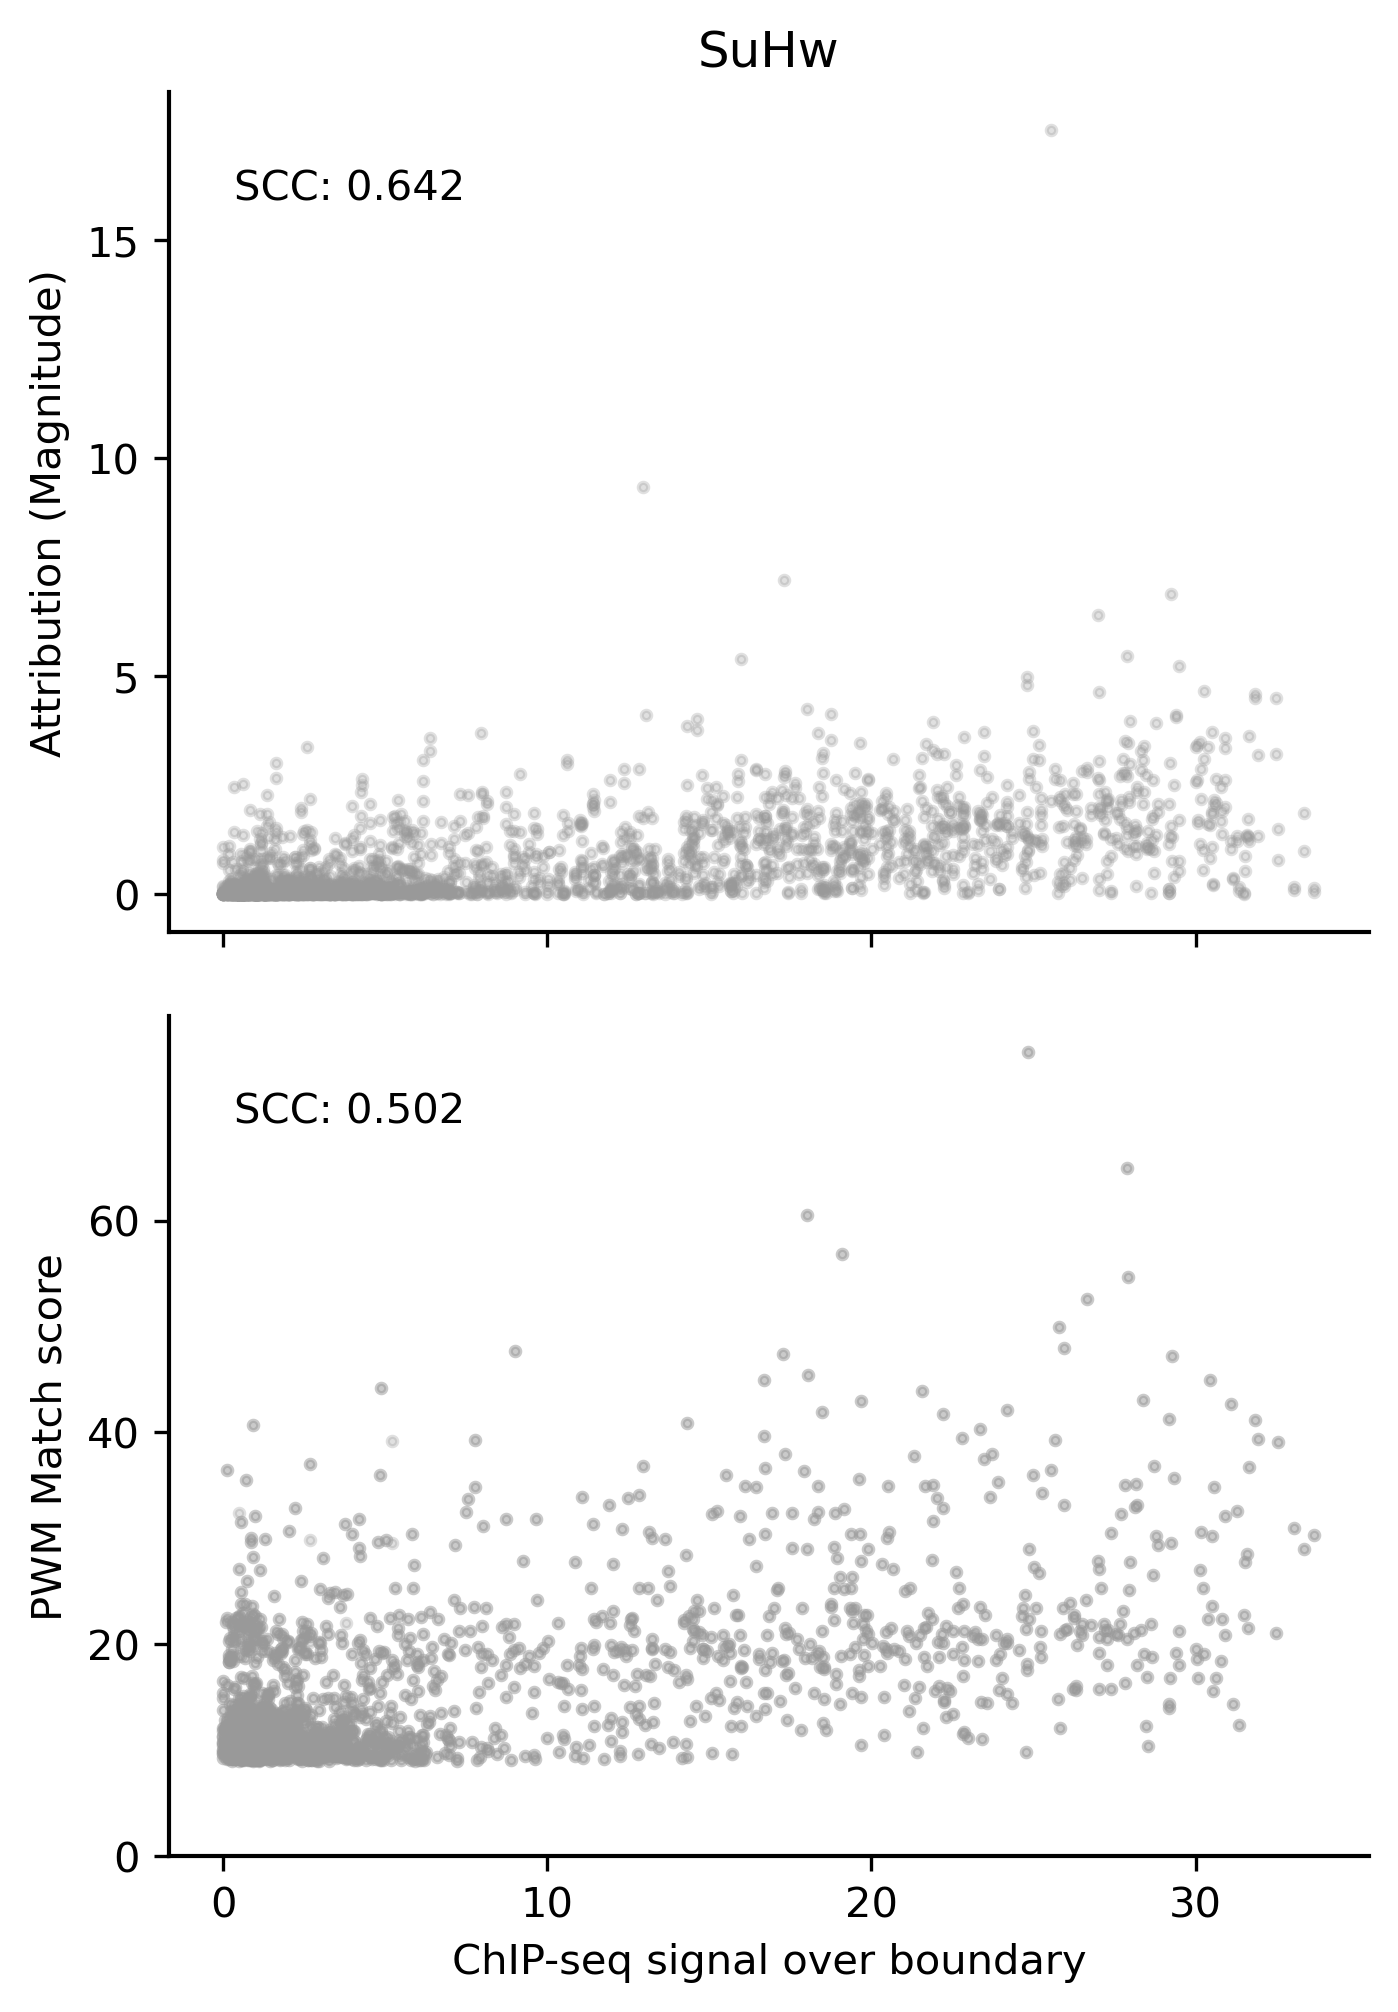

In [8]:

target = 'SuHw'
fig, axs = init_subplots_exact(2, 2, fgsz=(4,4), dpi=300, sharex=True, y_ratios=[0.7, 0.7], yspace=1.1)

ax=axs[0]
x, y = final_plot_df['chip'], final_plot_df['attribution']
ax.scatter(x, y, s=5, c=(0.6, 0.6, 0.6, 0.3))

pearson, spearman = stats.pearsonr(x, y)[0], stats.spearmanr(x, y)[0]
ax.text(max(x) * 0.01, max(y)*0.95, f'SCC: {spearman:.3f}',
     ha='left', va='top', color='black')
ax.set_yticks([0, 5, 10, 15])

ax.set_ylabel('Attribution (Magnitude)')
ax.spines['top'].set_visible(False)     
ax.spines['right'].set_visible(False)   
ax.spines['left'].set_edgecolor('black')  
ax.spines['left'].set_linewidth(1)      
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(1)  
ax.set_title(target)
axs[0].tick_params(labelbottom=False)

ax=axs[1]
x, y = final_plot_df['chip'], final_plot_df['score']
ax.scatter(x, y, s=5, c=(0.6, 0.6, 0.6, 0.3))

pearson, spearman = stats.pearsonr(x, y)[0], stats.spearmanr(x, y)[0]
ax.text(max(x) * 0.01, max(y)*0.95, f'SCC: {spearman:.3f}',
     ha='left', va='top', color='black')
ax.set_yticks([0, 20, 40, 60])
ax.set_xticks([0, 10, 20, 30])

ax.set_xlabel('ChIP-seq signal over boundary')
ax.set_ylabel('PWM Match score')
ax.spines['top'].set_visible(False)     
ax.spines['right'].set_visible(False)   
ax.spines['left'].set_edgecolor('black')  
ax.spines['left'].set_linewidth(1)      
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(1)  
# fig.savefig('plots/SuHw_chip_and_fimo_score.pdf', bbox_inches="tight")
plt.show()


## Do for all motifs

In [10]:
targets = ['GAGA', 'Zelda', 'Su(Hw)', 'BEAF-32', 'Pita', 'CTCF', 'M1BP', 'Ibf', 'Vostok', 'Mulberry', 'AAG3', 'Trem/CG4854']

motif_ids = list()
for motif_name in motifs.keys():
    for target in targets:
        if target in motif_name:
            motif_ids.append(motif_name)

import glob
import bbi

coords_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv')
bw_files = glob.glob('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/*.bw')

target2bbi = dict()
target2motifid = dict()

# target to bbi
for fn in bw_files:
    target = os.path.basename(fn).split('.')[0]
    target2bbi[target] = bbi.open(fn)

# target to motif ID
for fn in bw_files:
    target = os.path.basename(fn).split('.')[0]
    query = target
    # print(target)
    if target == 'suHw': query = 'Su(Hw)'
    if target == 'Trl': query = 'GAGA'
    if target == 'CG17385': query = 'AAG3'
    for identifier in motif_ids:
        if query in identifier: 
            target2motifid[target] = identifier
    
target2name = {
    'CTCF': 'CTCF',
    'Trl': 'Trl',
    'BEAF-32': 'BEAF-32',
    'M1BP': 'M1BP',
    'Ibf': 'Ibf',
    'Insv': 'Insv',
    'Mulberry': 'Mulberry',
}

In [11]:
score_pccs, score_sccs = list(), list()
attr_pccs, attr_sccs = list(), list()
target_names = list()

for target, motif_id in target2motifid.items():
    print(motif_id)
    hits = get_hits_df(motif_id, X, hits_)
    final_plot_df = get_final_plot_df(hits, target2bbi[target], coords_df)

    # score correlations
    x, y = 'score', 'chip'
    score_pccs.append(stats.pearsonr(final_plot_df[x], final_plot_df[y])[0])
    score_sccs.append(stats.spearmanr(final_plot_df[x], final_plot_df[y])[0])
    print('score scc', stats.spearmanr(final_plot_df[x], final_plot_df[y])[0])
    
    # attributions correlations
    x, y = 'attribution', 'chip'
    attr_pccs.append(stats.pearsonr(final_plot_df[x], final_plot_df[y])[0])
    attr_sccs.append(stats.spearmanr(final_plot_df[x], final_plot_df[y])[0])
    print('attr scc', stats.spearmanr(final_plot_df[x], final_plot_df[y])[0])
    
    target_names.append(target)

DOMINO Trem/CG4854


/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['sequence'] = seqs
/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['dist_from_center'] = np.abs(hits_df['start'] - center_pos)


score scc 0.23374325244938068
attr scc 0.38640753974685194
DOMINO Mulberry


/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['sequence'] = seqs
/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['dist_from_center'] = np.abs(hits_df['start'] - center_pos)


score scc 0.3522633995091261
attr scc 0.503780411515111
DOMINO BEAF-32


/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['sequence'] = seqs
/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['dist_from_center'] = np.abs(hits_df['start'] - center_pos)


... (15 outputs left out)

/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['sequence'] = seqs
/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['dist_from_center'] = np.abs(hits_df['start'] - center_pos)


score scc 0.2714287007537531
attr scc 0.6283274361216262
DOMINO GAGA


/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['sequence'] = seqs
/scratch/gpfs/PRITYKIN/brendan/domino/python_modules/plot_attributions_and_fimo.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_df['dist_from_center'] = np.abs(hits_df['start'] - center_pos)


score scc 0.515336200825733
attr scc 0.672490870738331


In [12]:
def plot_attribution_against_fimo(score_metrics, attr_metrics, target_names, metric="Spearman"):
    old_rc = plt.rcParams.copy()
    plt.rcParams['font.size'] = 16
    
    from adjustText import adjust_text
    fig, ax = plt.subplots()
    ax.scatter(score_metrics, attr_metrics, s=4, color='black')
    
    minx = float(min(min(score_metrics), min(attr_metrics)))
    maxx = float(max(max(score_metrics), max(attr_metrics)))
    ax.plot([minx,maxx], [minx, maxx], linestyle='dashed', lw=0.75, color='gray')
    
    texts = [ax.text(float(score_metrics[i]), float(attr_metrics[i]), target_names[i], fontsize=12, zorder=5) for i in range(len(target_names))]
    adjust_text(
        texts=texts,
        x=score_metrics, y=attr_metrics,
        ax=ax,
        expand_text=(2.0, 2.0),
        expand_points=(20.0, 20.0),     # increase distance from points
        force_text=0.5,               # push texts apart more gently
        arrowprops=dict(arrowstyle="-", color='black', lw=0.5, shrinkA=0.5),
        only_move={'points': 'y', 'text': 'xy'}  # customize movement directions
    )
    ax.spines['top'].set_visible(False)     
    ax.spines['right'].set_visible(False)   
    ax.spines['left'].set_edgecolor('black')  
    ax.spines['left'].set_linewidth(1)      
    ax.spines['bottom'].set_edgecolor('black')
    ax.spines['bottom'].set_linewidth(1)  
    plt.xlabel(f'PWM Match Score {metric}')
    plt.ylabel(f'Attribution {metric}')
    plt.show()
    # fig.savefig('plots/attribution_against_fimo_score_spearman.pdf', bbox_inches="tight", dpi=300)
    plt.rcParams.update(old_rc)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


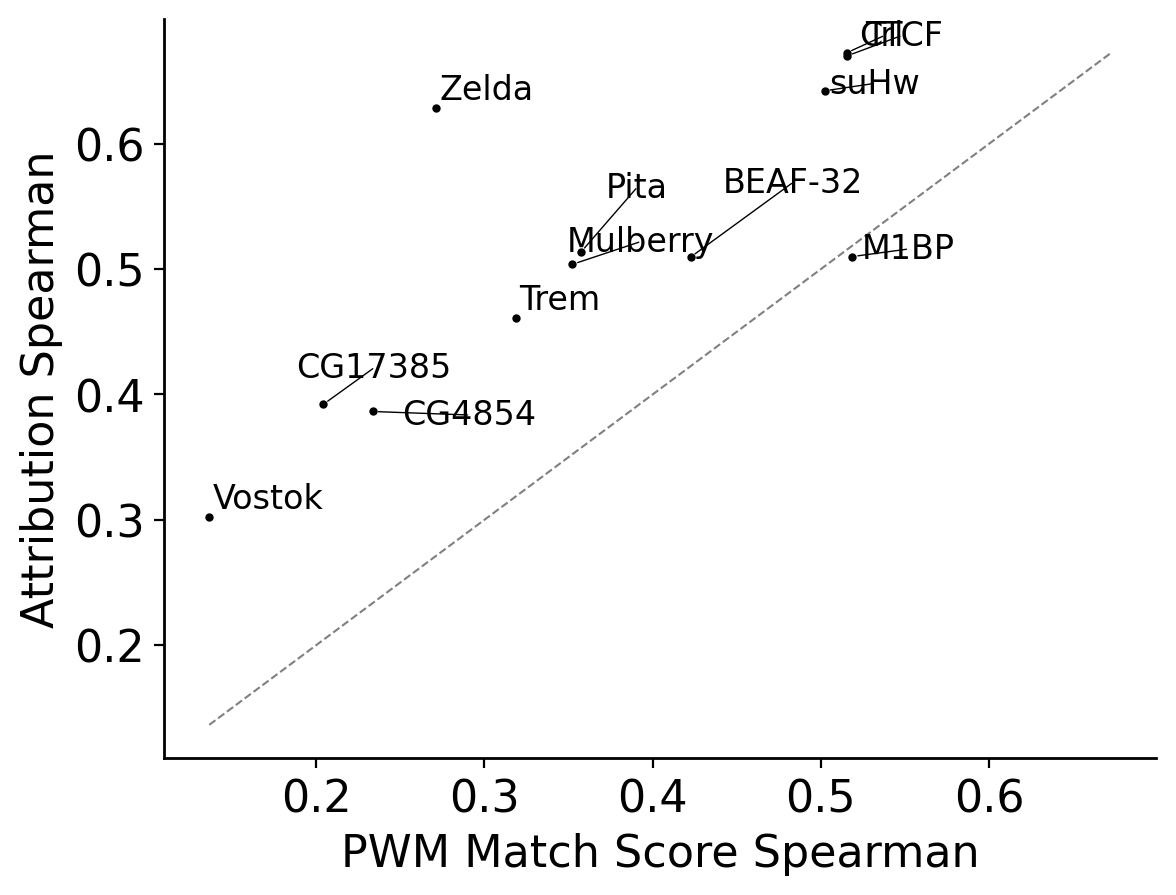

In [13]:
plot_attribution_against_fimo(score_sccs, attr_sccs, target_names, "Spearman")